# Sharpening an image

This notebook sharpens an AFM image in two ways, on the height data themselves. Sharpening is for looking at fine detail:
it changes the heights, so make your measurements on the unsharpened image. Run it from this folder, next to `grid.nid`.

In [1]:
from NSFopen.process import process

import matplotlib.pyplot as plt
from scipy.ndimage import laplace

In [2]:
afm = process("grid.nid", verbose=False)
afm.flatten(order=1)
z = afm.array()

## Unsharp mask

An unsharp mask adds the difference between the image and a blurred copy of it. `sigma` is the blur in pixels and `amount`
the strength.

## Laplacian

Subtracting the Laplacian, the local curvature of the image, sharpens the finest detail, with `amount` as its strength.

`set_channel` stores each result as a channel of its own, so the plots and the analysis can use them like any other.

In [3]:
unsharp = afm.filter_basic(inplace=False, kind="sharpen", sigma=2.0, amount=3.0)
afm.set_channel(unsharp, channel="Unsharp mask", unit="m")

afm.set_channel(z - 2.0 * laplace(z), channel="Laplacian", unit="m")

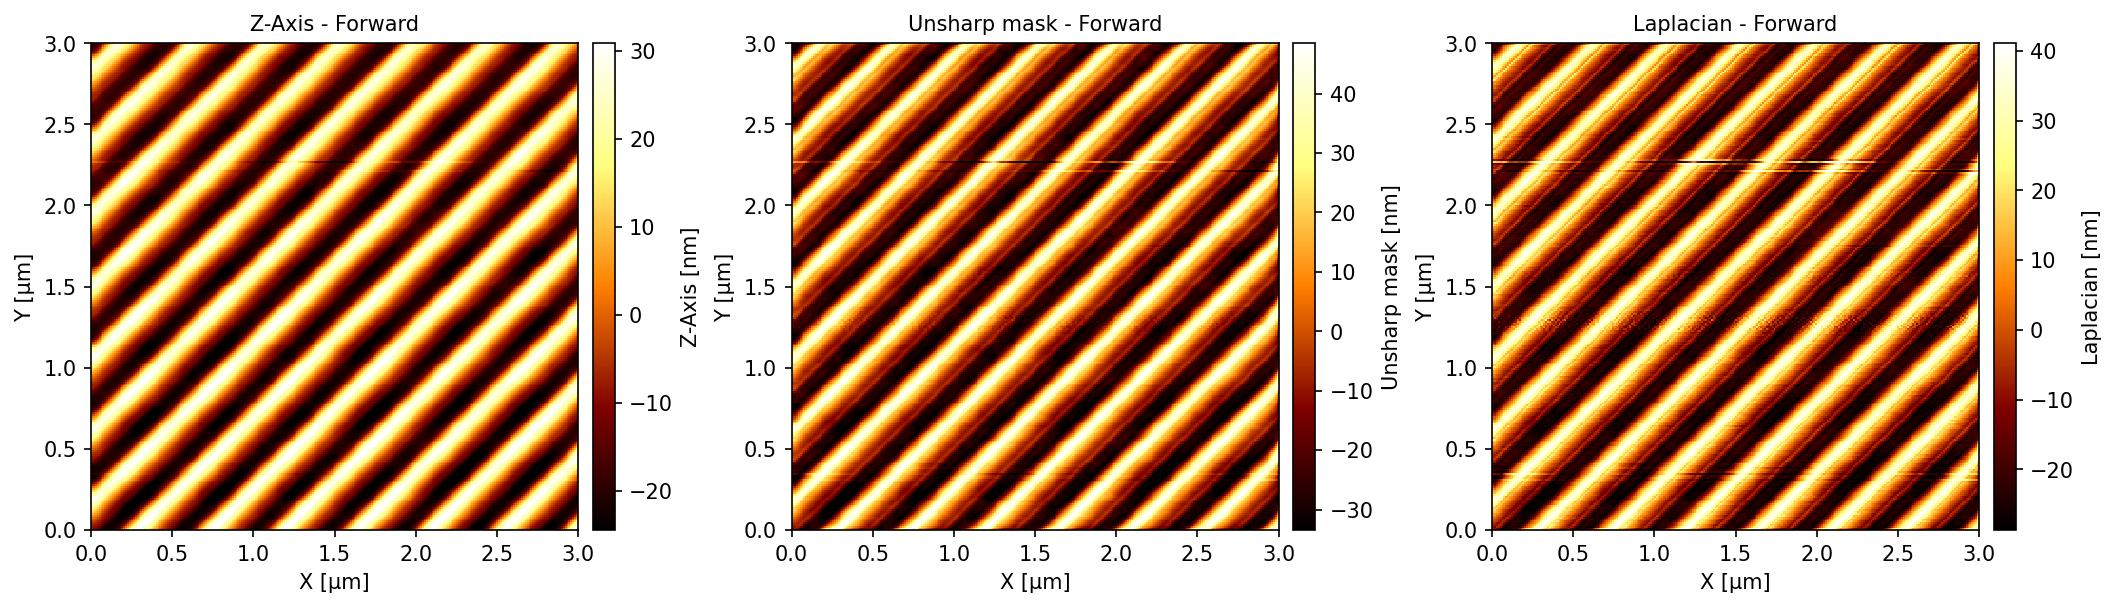

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), layout="constrained", dpi=150)
for ax, channel in zip(axes, ("Z-Axis", "Unsharp mask", "Laplacian")):
    afm.image(ax=ax, channel=channel, color_range="p1")
plt.show()

A line cut across all three shows what happens to the heights: edges get steeper, and the unsharp mask overshoots beside
them.

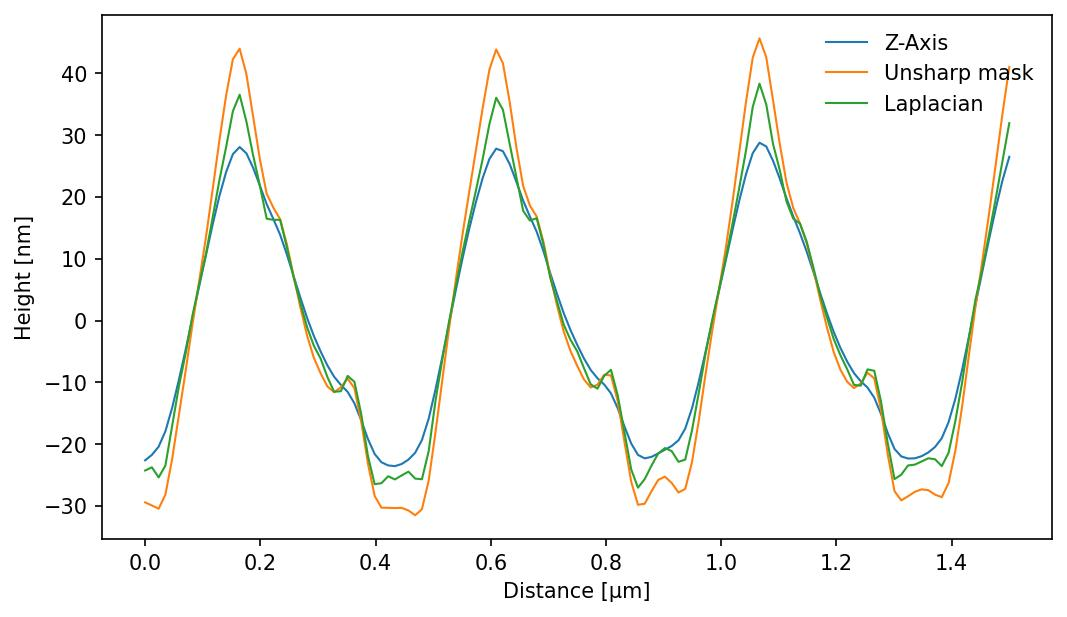

In [5]:
width, height = afm.size()
ends = (0.1 * width, 0.5 * height), (0.6 * width, 0.5 * height)

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained", dpi=150)
for channel in ("Z-Axis", "Unsharp mask", "Laplacian"):
    profile = afm.line_profile(*ends, channel=channel)
    ax.plot(profile.distance * 1e6, profile.mean * 1e9, label=channel, linewidth=1)
ax.set(xlabel="Distance [µm]", ylabel="Height [nm]")
ax.legend(frameon=False)
plt.show()